# Controlling the imputation

mice-py 0.4 adds four arguments to `impute`: `passive`, for R's passive imputation, and `post`,
`where` and `ignore`, which R's `mice()` has under the same names. R's `mice.mids()` is
`continue_chains`.

- `passive`: columns computed from other columns instead of imputed;
- `post`: a function that changes the imputations of a column right after they are drawn;
- `where`: which cells get an imputation;
- `ignore`: which rows the imputation models leave out;
- `continue_chains`: more iterations of the chains of a run.

The notebook uses R's `boys` data, introduced in `07_categorical_data.ipynb`, and assumes the
predictor matrix and the visit sequence of `03_advanced_parameters.ipynb`.

1. The data and the plan
2. Passive imputation
3. Post-processing
4. Which cells: `where`
5. Which rows the models use: `ignore`
6. Continuing a run
7. Fit and pool
8. R to mice-py

## 1. The data and the plan

`boys` holds age (years), height (`hgt`, cm), weight (`wgt`, kg), body mass index (`bmi`), head
circumference (`hc`, cm), genital development (`gen`), pubic hair (`phb`), testicular volume (`tv`,
ml) and region (`reg`) of 748 Dutch boys. As in notebook 07, `gen` and `phb` are declared as
ordered categoricals. The table shows the missing values per column, and how many of them belong
to the 291 boys under 5:

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from imputation import MICE
from plotting import densityplot, plot_chain_stats

plt.rcParams["figure.dpi"] = 72  # keeps the stored images small

boys_csv = pd.read_csv("data/boys.csv")
boys = boys_csv.assign(
    gen=pd.Categorical(boys_csv["gen"], categories=["G1", "G2", "G3", "G4", "G5"], ordered=True),
    phb=pd.Categorical(boys_csv["phb"], categories=["P1", "P2", "P3", "P4", "P5", "P6"], ordered=True),
)
under_5 = boys["age"] < 5
pd.DataFrame({"dtype": boys.dtypes, "missing": boys.isna().sum(), "of them under 5": boys[under_5].isna().sum()})

,dtype,missing,of them under 5
age,float64,0,0
hgt,float64,20,17
wgt,float64,4,1
bmi,float64,21,18
hc,float64,46,10
gen,category,503,291
phb,category,503,291
tv,float64,522,291
reg,object,3,3


Five problems of these data, and the feature of mice-py that solves each:

| Problem | Feature | Section |
|---|---|---|
| `bmi` is `wgt / (hgt / 100) ** 2`; imputed on its own, it no longer is | `passive` | 2 |
| `tv` lies between 1 and 25 ml; `norm` imputes values outside | `post` | 3 |
| Cells that should stay missing; observed cells to check the imputation model on | `where` | 4 |
| Rows that must not influence the imputation models, such as a test set | `ignore` | 5 |
| Five iterations, the default, may be too few | `continue_chains` | 6 |

Sections 2 and 3 build the settings that section 6 runs; sections 4 and 5 use the default
methods. Every `impute` call has a seed, so the outputs can be reproduced.

## 2. Passive imputation

In the data, `bmi` equals `wgt / (hgt / 100) ** 2`, rounded to two decimals. `bmi` is missing in
21 rows: those where `hgt`, `wgt` or both are missing. By default `bmi` gets `pmm` like any numeric
column and is imputed from the other columns; nothing ties it to the `hgt` and `wgt` imputed in
the same row. For the rows with a missing `bmi`: the largest difference between the imputed `bmi`
and the one computed from the completed `hgt` and `wgt`, per dataset, and the first rows of the
first dataset:

In [2]:
missing_bmi = boys["bmi"].isna()


def bmi_from(data):
    return data["wgt"] / (data["hgt"] / 100) ** 2


def largest_difference(datasets):
    return [round(float((data["bmi"] - bmi_from(data))[missing_bmi].abs().max()), 2) for data in datasets]


print("observed rows, largest difference:", round(float((boys["bmi"] - bmi_from(boys)).abs().max()), 2))

mice_pmm = MICE(boys)
mice_pmm.impute(seed=1)
print("imputed rows, largest difference per dataset:", largest_difference(mice_pmm.imputed_datasets))

first = mice_pmm.imputed_datasets[0]
first.loc[missing_bmi, ["age", "hgt", "wgt", "bmi"]].assign(computed=bmi_from(first)).round(2).head()

observed rows, largest difference: 0.01


imputed rows, largest difference per dataset: [15.33, 22.76, 29.63, 18.37, 23.25]


,age,hgt,wgt,bmi,computed
17,0.09,60.5,4.54,14.49,12.40
51,0.18,57.5,10.72,17.09,32.42
173,1.48,77.5,12.04,16.31,20.05
177,1.49,91.1,11.50,12.56,13.86
183,1.53,82.0,12.40,16.76,18.44


In the observed rows the two differ by the rounding only; in the imputed rows by much more.

A **passive** column is computed instead of imputed. `passive` maps the column to a function of
the data, here `bmi_from`. At each visit of `bmi`, the function gets a copy of the data the chains
work on, with the current imputations, and returns one value per row; the missing cells of `bmi`
take the values of their rows. A first try, with the default predictor matrix. The table shows the
imputed weights of the four boys whose weight is missing, one column per dataset:

In [3]:
missing_wgt = boys["wgt"].isna()


def imputed_weights(mice):
    weights = {f"dataset {i}": data.loc[missing_wgt, "wgt"] for i, data in enumerate(mice.imputed_datasets, 1)}
    return pd.DataFrame({"age": boys.loc[missing_wgt, "age"], **weights}).round(2)


mice_feedback = MICE(boys)
mice_feedback.impute(passive={"bmi": bmi_from}, seed=1)
print("largest difference per dataset:", largest_difference(mice_feedback.imputed_datasets))
imputed_weights(mice_feedback)

largest difference per dataset: [0.0, 0.0, 0.0, 0.0, 0.0]


,age,dataset 1,dataset 2,dataset 3,dataset 4,dataset 5
51,0.18,94.4,113.0,94.9,102.00,31.8
301,5.82,93.8,37.0,113.0,4.07,17.7
413,11.70,57.5,53.5,36.5,34.10,46.2
723,19.53,94.9,99.0,78.0,97.00,77.5


`bmi` now equals the function of `hgt` and `wgt` in every row with a missing `bmi`, but the imputed
weights are not plausible: see the first row, a boy aged two months. By default every column
predicts every other, so `bmi` predicts `hgt` and `wgt`. `wgt` is then imputed from a `bmi` that
was computed from the imputed `wgt` of the previous iteration: an implausible weight gives an
implausible `bmi`, which predicts the next weight. The entries of `hgt` and `wgt` in the column of
`bmi` must be 0, so that `bmi` does not predict its own inputs; it still predicts the other
columns. This is R's practice too. A passive column has no model, so its own row of the matrix is
not used.

In [4]:
predictors = pd.DataFrame(1, index=boys.columns, columns=boys.columns) - np.eye(len(boys.columns), dtype=int)
predictors.loc[["hgt", "wgt"], "bmi"] = 0  # bmi is computed from hgt and wgt: it does not predict them

mice_passive = MICE(boys)
mice_passive.impute(passive={"bmi": bmi_from}, predictor_matrix=predictors, seed=1)
print("largest difference per dataset:", largest_difference(mice_passive.imputed_datasets))
print(mice_passive.method)
print(mice_passive.visit_sequence)
imputed_weights(mice_passive)

largest difference per dataset: [0.0, 0.0, 0.0, 0.0, 0.0]
{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'passive', 'hc': 'pmm', 'gen': 'polr', 'phb': 'polr', 'tv': 'pmm', 'reg': 'polyreg'}
['hgt', 'wgt', 'hc', 'gen', 'phb', 'tv', 'reg', 'bmi']


,age,dataset 1,dataset 2,dataset 3,dataset 4,dataset 5
51,0.18,7.78,5.05,8.6,6.26,4.43
301,5.82,21.10,18.00,18.0,24.50,15.50
413,11.70,34.50,30.30,39.8,43.50,34.10
723,19.53,88.00,60.50,67.0,68.80,76.80


In every completed dataset the imputed `bmi` equals the function of `hgt` and `wgt`, and the
imputed weights fit the ages.

- **`mice.method`** shows `"passive"` for `bmi`. It is not a method name: `method` does not take
  it, and a `method` dict must not name a passive column.
- **The visit order.** By default the passive columns are visited last, as in R, so `bmi` is
  computed from the `hgt` and `wgt` of the same iteration; the columns visited before it (`hc` to
  `reg`) are predicted from the `bmi` of the previous iteration. A list places a passive column
  anywhere, for example right after its inputs:
  `visit_sequence=["hgt", "wgt", "bmi", "hc", "gen", "phb", "tv", "reg"]`.
- **From R.** R writes the passive column as a method, `meth["bmi"] <- "~ I(wgt / (hgt / 100)^2)"`,
  and evaluates the formula on the rows being imputed only. The function of `passive` gets all
  rows; this matters only for a function that is not row-wise, such as one that subtracts the mean
  of a column.

## 3. Post-processing

`tv` is observed between 1 and 25 ml, for 226 boys, the youngest of them 8.9 years old; it is
missing for 522 boys, among them all 291 boys under 5. `norm` imputes from a normal linear
regression, so it can impute values outside that range. The imputed volumes under `norm` (the five
datasets together): the smallest and the largest, the share below 0, the shares at exactly 1 and at
25, and the share at 1 among the boys under 5:

In [5]:
missing_tv = boys["tv"].isna()


def tv_summary(mice):
    imputed = pd.concat([data.loc[missing_tv, ["age", "tv"]] for data in mice.imputed_datasets])
    tv, young = imputed["tv"], imputed["age"] < 5
    return {
        "min": tv.min(),
        "max": tv.max(),
        "below 0": (tv < 0).mean(),
        "at 1": (tv == 1).mean(),
        "at 25": (tv == 25).mean(),
        "under 5: at 1": (tv[young] == 1).mean(),
    }


mice_norm = MICE(boys)
mice_norm.impute(method={"tv": "norm"}, seed=1)
pd.DataFrame({"norm": tv_summary(mice_norm)}).T.round(2)

,min,max,below 0,at 1,at 25,under 5: at 1
norm,-21.41,30.81,0.46,0.0,0.0,0.0


Many imputed volumes are negative, a volume no boy has, and some exceed 25.

`post` maps a column to a function `f(imp, data)` that is called right after each imputation of
the column, in every iteration and chain. `imp` holds the current imputations of the column (of its
missing cells by default; see `where` in section 4), a Series indexed by their row labels; `data`
holds the data the chains work on, in the same rows, all columns. `f` returns the values to keep.
They replace the imputations; the next columns are imputed from them, and the chain statistics are
taken after them. `Series.clip` bounds the values, as R's `squeeze()`:

In [6]:
mice_clip = MICE(boys)
mice_clip.impute(method={"tv": "norm"}, post={"tv": lambda imp, data: imp.clip(1, 25)}, seed=1)
pd.DataFrame({"norm": tv_summary(mice_norm), "norm, clip": tv_summary(mice_clip)}).T.round(2)

,min,max,below 0,at 1,at 25,under 5: at 1
norm,-21.41,30.81,0.46,0.00,0.00,0.00
"norm, clip",1.00,25.00,0.00,0.51,0.03,0.85


All imputed volumes now lie between 1 and 25. Clipping moves every value outside the range to the
nearer bound, so many imputations are exactly 1 (`at 1`): the values are possible, but the model
is still the linear regression that imputed them.

**A rule that reads another column.** `data` holds the other columns of the same rows, with their
current imputations. No boy under 5 has an observed volume, and most of their imputations are
already at the lower bound (`under 5: at 1`). The rule below sets the volume of every boy under 5
to the smallest observed volume, 1 ml, and bounds the others:

In [7]:
def tv_rule(imp, data):
    return imp.clip(1, 25).where(data["age"] >= 5, 1)


mice_rule = MICE(boys)
mice_rule.impute(method={"tv": "norm"}, post={"tv": tv_rule}, seed=1)
pd.DataFrame(
    {"norm": tv_summary(mice_norm), "norm, clip": tv_summary(mice_clip), "norm, rule": tv_summary(mice_rule)}
).T.round(2)

,min,max,below 0,at 1,at 25,under 5: at 1
norm,-21.41,30.81,0.46,0.00,0.00,0.00
"norm, clip",1.00,25.00,0.00,0.51,0.03,0.85
"norm, rule",1.00,25.00,0.00,0.59,0.03,1.00


Every boy under 5 now has the volume 1 in every dataset.

From R: R's `post` is a string of R code that changes `imp[[j]][, i]`,
`post["tv"] <- "imp[[j]][, i] <- squeeze(imp[[j]][, i], c(1, 25))"`; in mice-py it is a function
that returns the new values. `post` must not name a passive column: R ignores such an entry,
mice-py raises `ValueError`; put the change into the function of `passive`.

## 4. Which cells: `where`

A cell that gets an imputation is a **where-cell**. By default the where-cells are the missing
cells, as in R. `where` takes R's keywords (`"missing"`, `"all"`, `"observed"`, `"none"`) or a
boolean DataFrame with the index and the column labels of the data. To change single cells, start
from `boys.isna()`, the default, and edit it. The columns of the frame are aligned by label; R
takes them by position.

### 4.1 Leaving cells unimputed

Section 3 set the volume of the boys under 5 to 1. Another choice is not to impute it: `where` is
False for these cells. Per column: the missing values in the data, the where-cells, and the missing
values left in the first completed dataset:

In [8]:
where_young = boys.isna()
where_young.loc[under_5, "tv"] = False  # leave the tv of the boys under 5 missing

mice_young = MICE(boys)
mice_young.impute(where=where_young, seed=1)
pd.DataFrame(
    {
        "missing": boys.isna().sum(),
        "where-cells": where_young.sum(),
        "missing after": mice_young.imputed_datasets[0].isna().sum(),
    }
)

,missing,where-cells,missing after
age,0,0,0
hgt,20,20,17
wgt,4,4,1
bmi,21,21,18
hc,46,46,10
gen,503,503,291
phb,503,503,291
tv,522,231,291
reg,3,3,3


Not only `tv` of the boys under 5 stays missing: compare `missing after` with the column
`of them under 5` in section 1. A where-cell is imputed only where all its predictors are complete
in its row, and `tv` predicts every other column, so none of the missing cells of the boys under 5
is imputed. R does the same.

If the other columns are to be imputed, `tv` must not predict them: set its column of the predictor
matrix to 0. `tv` is then imputed from the other columns but predicts none of them:

In [9]:
tv_predicts_nothing = pd.DataFrame(1, index=boys.columns, columns=boys.columns) - np.eye(len(boys.columns), dtype=int)
tv_predicts_nothing["tv"] = 0

mice_young = MICE(boys)
mice_young.impute(where=where_young, predictor_matrix=tv_predicts_nothing, seed=1)
mice_young.imputed_datasets[0].isna().sum()

age      0
hgt      0
wgt      0
bmi      0
hc       0
gen      0
phb      0
tv     291
reg      0
dtype: int64

Only the left-out volumes stay missing. The price is that `tv` no longer helps to impute `gen` and
`phb`. Imputing `tv` and setting it with `post`, as in section 3, keeps it as a predictor.

### 4.2 Imputing observed cells

Where `where` marks an observed cell, the completed datasets hold an imputation there, which can be
compared with the value observed there: a check of the imputation model. Here 150 observed weights,
drawn at random, are marked. In the data the chains work on, an observed where-cell keeps its
observed value, as in R, so the model of `wgt` is fitted on it and the other columns are predicted
from it. Per dataset: the mean absolute difference between the imputed and the observed weights
(kg), their correlation, and the share of imputations equal to the observed weight:

In [10]:
marked = boys[boys["wgt"].notna()].sample(150, random_state=1).index
where_check = boys.isna()
where_check.loc[marked, "wgt"] = True

mice_check = MICE(boys)
mice_check.impute(where=where_check, seed=1)

observed_wgt = boys.loc[marked, "wgt"]
imputed_wgt = pd.concat([data.loc[marked, "wgt"] for data in mice_check.imputed_datasets], axis=1)
imputed_wgt.columns = range(1, len(mice_check.imputed_datasets) + 1)
pd.DataFrame(
    {
        "mean abs. difference": imputed_wgt.sub(observed_wgt, axis=0).abs().mean(),
        "correlation": imputed_wgt.corrwith(observed_wgt),
        "equal": imputed_wgt.eq(observed_wgt, axis=0).mean(),
    }
).rename_axis("dataset").round(3)

,mean abs. difference,correlation,equal
dataset,,,
1,2.306,0.993,0.100
2,2.102,0.993,0.160
3,2.102,0.994,0.107
4,2.184,0.992,0.153
5,2.429,0.991,0.127


The observed weights range from 3 to 117 kg; the imputations lie close to them. Some imputations
equal the observed weight exactly (`equal`). `pmm` imputes observed values of donors, and a marked
cell keeps its observed value in the data the model is fitted on, so that value is one of the
candidates; the check is somewhat optimistic for `pmm`.

### 4.3 Marked cells that cannot be imputed

An observed where-cell is imputed only where its predictors are complete, too. Below, the weights of
4.2 are marked and the volumes of the boys under 5 left missing, as in 4.1, with the default
predictor matrix. The marked weights of the boys under 5 cannot be imputed: they are missing in the
completed datasets, and their observed values are lost. R does this silently; mice-py warns once,
with the number of lost values per column (the warning is caught here to print its text):

In [11]:
where_both = where_young.copy()
where_both.loc[marked, "wgt"] = True

mice_both = MICE(boys)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    mice_both.impute(where=where_both, seed=1)
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")

print("marked weights of boys under 5:", under_5[marked].sum())
print("missing weights in the first dataset:", mice_both.imputed_datasets[0]["wgt"].isna().sum())

marked weights of boys under 5: 57
missing weights in the first dataset: 58


The lost values are the marked weights of the boys under 5; with the one missing weight of a boy
under 5, which is not imputed either, they are the missing weights of the completed data. Mark only
cells whose predictors are observed or imputed in their row, or change the predictor matrix as in
4.1.

### 4.4 Plots

The plot functions take a frame that is True for the cells that were not imputed and False for the
imputed ones. With the default `where` that is `boys.notna()`; after a run with `where` it is
`~mice.where`. With `boys.notna()`, the 150 marked weights would count as observed, and the
observed curve would include their imputations. R's plots group the cells by `is.na(data)`,
whatever `where` was. The weights of 4.2, observed (blue) and imputed (red, one curve per dataset):

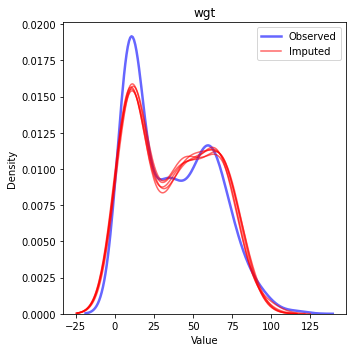

In [12]:
densityplot(mice_check.imputed_datasets, ~mice_check.where, columns=["wgt"]);

The red curves, of the 150 marked weights and the 4 missing ones, have the two peaks of the blue
curve of the other observed weights.

## 5. Which rows the models use: `ignore`

`ignore` takes one boolean per row. An ignored row is left out of the model of every column in
every iteration, and its observed values are not drawn as start values; its where-cells are imputed
like any other, from the models fitted on the other rows.

The typical use is a training set and a test set: the test rows must be imputed, but must not
influence the imputation models. R does this with `mice.mids(newdata = )` or with `ignore`; mice-py
has no `newdata`, and does it with `ignore`. Put the two sets together, ignore the test rows, and
take their completed rows. Here the test set is 150 boys drawn at random:

In [13]:
test = boys.sample(150, random_state=1)
train = boys.drop(test.index)

both = pd.concat([train, test], ignore_index=True)
ignore = np.arange(len(both)) >= len(train)  # True for the rows of test

mice_split = MICE(both)
mice_split.impute(ignore=ignore, seed=1)
test_completed = [data.iloc[len(train) :].set_axis(test.index) for data in mice_split.imputed_datasets]

print(f"rows: {len(train)} training, {mice_split.ignore.sum()} ignored")
print(f"observed tv: {train['tv'].notna().sum()} training rows, {test['tv'].notna().sum()} test rows")
pd.DataFrame({"missing in test": test.isna().sum(), "after": test_completed[0].isna().sum()})

rows: 598 training, 150 ignored
observed tv: 179 training rows, 47 test rows


,missing in test,after
age,0,0
hgt,3,0
wgt,1,0
bmi,3,0
hc,10,0
gen,97,0
phb,96,0
tv,103,0
reg,0,0


Imputed on its own, the test set would fit the model of `tv` on its few observed volumes; imputed
with the training set but without `ignore`, its rows would enter the models. With `ignore`, the
models are fitted on the training rows, and the test rows are complete in every dataset.
`set_axis(test.index)` gives them back the row labels they have in `boys`. The training rows are
imputed in the same run, from the same models. As in R, `logreg`, `polyreg` and `polr` (here `gen`,
`phb` and `reg`) take the ignored rows into the rows they add to the data (R's augmentation).

## 6. Continuing a run

The settings of sections 2 and 3 together: the passive `bmi` with its predictor matrix, and `tv`
imputed by `norm` with the rule of section 3. First the default five iterations, and the trace
plot of `tv`: the mean and the standard deviation of its imputations at the end of each iteration,
one line per chain.

sd of tv per chain, iteration 1: [7.49 6.98 7.07 7.36 6.75]  iteration 5: [8.07 7.9  7.46 7.79 7.93]


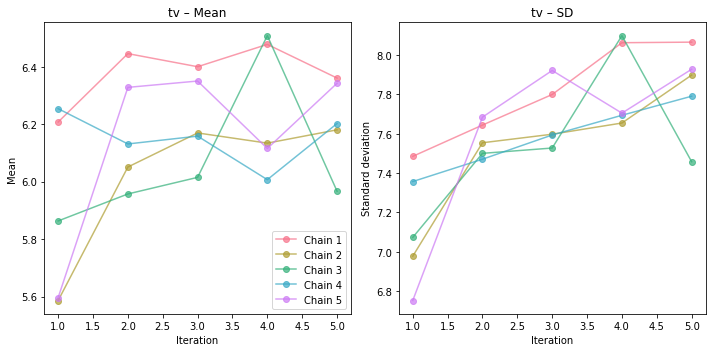

In [14]:
plan = {
    "method": {"tv": "norm"},
    "predictor_matrix": predictors,
    "passive": {"bmi": bmi_from},
    "post": {"tv": tv_rule},
}

mice = MICE(boys)
mice.impute(maxit=5, seed=1, **plan)
sd_tv = np.sqrt(mice.chain_var["tv"])  # one row per iteration, one column per chain
print("sd of tv per chain, iteration 1:", sd_tv[0].round(2), " iteration 5:", sd_tv[4].round(2))
plot_chain_stats(mice.chain_mean, mice.chain_var, columns=["tv"]);

In every chain the standard deviation of `tv` is higher at the fifth iteration than at the first:
five iterations do not show where the chains settle.
`continue_chains(15)` runs 15 more iterations of the same chains, as R's
`mice.mids(imp, maxit = 15)`: each chain goes on from its current imputations and from its random
generator where it stopped, with the methods, the predictor matrix, the visit sequence, `where`,
`ignore`, `post` and `passive` of the run. `chain_mean` and `chain_var` get one row per new
iteration, so the plot shows all 20:

iterations: 20  chain_mean of tv: (20, 5)


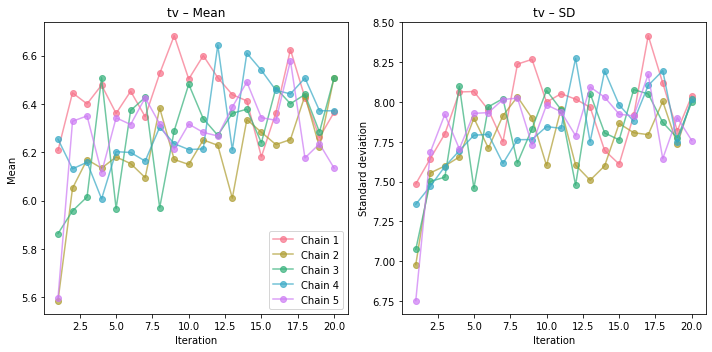

In [15]:
mice.continue_chains(15)
print("iterations:", mice.iteration, " chain_mean of tv:", mice.chain_mean["tv"].shape)
plot_chain_stats(mice.chain_mean, mice.chain_var, columns=["tv"]);

After the first few iterations the lines move around a stable level, without a trend, and the
chains mix. The result equals one run of 20 iterations with the same seed, as long as the functions
of `post` and `passive` give the same values for the same input (a function that draws random
numbers does not):

In [16]:
mice_20 = MICE(boys)
mice_20.impute(maxit=20, seed=1, **plan)

same_data = all(a.equals(b) for a, b in zip(mice.imputed_datasets, mice_20.imputed_datasets))
same_chains = all(np.array_equal(mice.chain_mean[col], mice_20.chain_mean[col]) for col in mice.chain_mean)
print("same completed datasets:", same_data)
print("same chain means:", same_chains)

same completed datasets: True
same chain means: True


## 7. Fit and pool

As in `04_analysis_workflow.ipynb`: fit a model to each of the five completed datasets of section 6
and pool the fits with Rubin's rules. `bmi` is the passive column, consistent with `hgt` and `wgt`
in every dataset.

In [17]:
mice.fit("bmi ~ age + reg")
table = mice.pool()["table"]
table[["estimate", "std_error", "df", "p_value", "fmi"]].round(3)

,estimate,std_error,df,p_value,fmi
term,,,,,
Intercept,15.987,0.297,723.760,0.000,0.011
reg[T.east],-0.654,0.335,736.560,0.051,0.006
reg[T.north],0.114,0.390,631.958,0.770,0.031
reg[T.south],-0.620,0.327,728.808,0.058,0.010
reg[T.west],-0.504,0.319,697.233,0.114,0.018
age,0.274,0.013,731.206,0.000,0.009


`bmi` is missing for 21 boys and `reg` for 3, so the fractions of missing information (`fmi`) are
small.

A new `impute` or `continue_chains` replaces the completed datasets and removes the fits, so that
`pool` cannot combine fits of datasets that are gone. Call `fit` again after either:

In [18]:
mice.continue_chains(1)
print("fits:", len(mice.model_results))
try:
    mice.pool()
except ValueError as error:
    print(f"ValueError: {error}")

fits: 0
ValueError: No model results found. Please run .fit() first.


## 8. R to mice-py

| R mice | mice-py |
|---|---|
| `meth["bmi"] <- "~ I(wgt / (hgt / 100)^2)"` | `impute(passive={"bmi": lambda d: d["wgt"] / (d["hgt"] / 100) ** 2})` |
| `pred[c("hgt", "wgt"), "bmi"] <- 0` | `predictors.loc[["hgt", "wgt"], "bmi"] = 0` |
| `post["tv"] <- "imp[[j]][, i] <- squeeze(imp[[j]][, i], c(1, 25))"` | `impute(post={"tv": lambda imp, data: imp.clip(1, 25)})` |
| `mice(boys, where = w)` | `impute(where=w)`: a keyword, a boolean DataFrame or a boolean array |
| `make.where(boys)`, `make.where(boys, "all")` | `boys.isna()` (a frame to edit), `where="all"` |
| `mice(boys, ignore = v)` | `impute(ignore=v)` |
| `mice.mids(imp, newdata = test)` | the `ignore` recipe of section 5 |
| `imp <- mice.mids(imp, maxit = 15)` | `mice.continue_chains(15)` |
| `imp$where`, `imp$ignore`, `imp$post`, `imp$iteration` | `mice.where`, `mice.ignore`, `mice.post`, `mice.iteration`; `mice.passive` |
| `plot(imp)` | `plot_chain_stats(mice.chain_mean, mice.chain_var)` |
| `densityplot(imp)` | `densityplot(mice.imputed_datasets, ~mice.where)` |
| `pool(with(imp, lm(bmi ~ age + reg)))` | `mice.fit("bmi ~ age + reg")`, then `mice.pool()` |

## Summary

- `passive` computes a column from the others at each of its visits, so a derived column such as
  `bmi` stays consistent with its inputs. Set the entries of its inputs in its column of the
  predictor matrix to 0.
- `post` changes the imputations of a column right after they are drawn: bounds with
  `Series.clip`, or rules that read other columns from `data`.
- `where` chooses the where-cells. A where-cell is imputed only where its predictors are complete;
  cells left out spread to the columns they predict, and observed where-cells that cannot be
  imputed are lost, with a warning. Pass `~mice.where` to the plots.
- `ignore` leaves rows out of the models while imputing them: the recipe for a test set.
- `continue_chains` runs more iterations of the same chains, with the same result as one longer
  run, and removes the fits of the earlier datasets.

Next: the user guide pages Controlling the Imputation and Convergence Diagnostics, and Differences
from R mice for every case in which these arguments behave differently from R's.